# 08 — Frozen semantic embeddings + logistic regression

Test a different text representation, keeping the evaluation fixed. A frozen `sentence-transformers/all-MiniLM-L6-v2` encoder maps each chunk to a semantic vector. Average and normalise chunks **within each field**, then concatenate title, company profile, description, requirements and benefits in a fixed order. Empty fields are zero vectors. No structured A2 features are added in this experiment.

The encoder is not trained on our labels. Its deterministic, row-wise embeddings can be cached before cross-validation. Only the logistic classifier learns from the fraud labels; its C and cutoff are chosen inside training folds. All 25 outer folds come from notebook 02. The reserved test set is never read.

## How to run, entirely in the notebook

Use the project's `.venv` environment in a separate kernel. First run the setup cell. If the optional packages are missing, set `INSTALL_DEPENDENCIES=True` in the installation cell and run that cell, then restart this notebook's kernel and run from the top. Existing core numerical package versions are constrained during installation.

Set `BUILD_EMBEDDINGS=True` to download the encoder and build cached vectors. Set `TRAIN_MODEL=True` to evaluate the classifier. Both are off initially so Run All can safely inspect existing results. Initial model download needs internet; actual encoding is local. Subsequent complete embedding caches need neither download nor encoding.

**Resume:** completed embedding batches and completed outer folds are saved and reused. An interrupted embedding batch or outer fold restarts; finished work remains. Keep the model, data, software, chunk settings and code unchanged when resuming. New configurations require new cache/report folders.

Sources: [encoder model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), [SentenceTransformer API](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html). This model's normal input limit is short relative to job ads, so chunks are checked against the loaded encoder limit instead of silently truncating long ads. Generic semantic pretraining does not establish fraud-detection quality. A gain must be demonstrated here.

In [8]:
import hashlib
import html
import importlib.metadata
import importlib.util
import json
from pathlib import Path
import re
import subprocess
import sys
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluation import (validate_folds, fold_signature, score_summary, summarise,
                            paired_comparison, select_settings)

BUILD_EMBEDDINGS = True
TRAIN_MODEL = True
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
DEVICE = 'cpu'  # CPU is the reproducible default; changing device changes the cache plan.
FIELDS = ['title', 'company_profile', 'description', 'requirements', 'benefits']
CHUNK_TOKENS = 192
CHUNK_OVERLAP = 32
ROWS_PER_BATCH = 64
ENCODE_BATCH_SIZE = 32
THREADS = 2
SEED = 42
INNER_SPLITS = 3
C_GRID = {'model__C': [0.1, 0.3, 1.0]}
CACHE_DIR = ROOT / 'data/processed/semantic_minilm_fields_v1'
REPORT_DIR = ROOT / 'reports/classifier_semantic_embeddings'
PREDICTION_DIR = ROOT / 'data/processed/classifier_semantic_embeddings'
MODEL_CACHE = ROOT / 'data/processed/pretrained_models'

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)

def save_array(path, values):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    with temporary.open('wb') as stream:
        np.save(stream, values, allow_pickle=False)
    temporary.replace(path)

print('Embedding build:', BUILD_EMBEDDINGS, '| Classifier training:', TRAIN_MODEL)
print('Optional encoder dependencies installed:', bool(importlib.util.find_spec('sentence_transformers')))

Embedding build: True | Classifier training: True
Optional encoder dependencies installed: True


In [9]:
# Optional one-time installation. No shell/terminal needed. Restart this kernel afterward.
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib', 'threadpoolctl']
    with tempfile.TemporaryDirectory(prefix='bt4012_semantic_install_') as folder:
        constraints = Path(folder) / 'constraints.txt'
        constraints.write_text('\n'.join(f'{p}=={importlib.metadata.version(p)}' for p in packages))
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install',
            '--timeout', '120',
            '--retries', '8',
            '-c', str(constraints),
            'sentence-transformers>=5,<6'
        ])
    print('Installation completed. Restart this notebook kernel before continuing.')
else:
    print('Installation skipped. Enable only if the encoder dependencies are missing.')

Installation skipped. Enable only if the encoder dependencies are missing.


## 1. Load only training data, recover exact folds and reuse completed references

The two 02 baseline prediction files are checked against their saved metrics. Additional 03/04 score tables must match the same fold signatures. Baseline training-time source/package manifests were not saved by 02, so historical inner-fold reproducibility cannot be fully proven. No baseline is retrained.

In [10]:
BASELINES = {'logreg_text_30k': 'logreg_tf_idf_only', 'logreg_a2_30k': 'logreg_a2'}
NAMES = {'logreg_text_30k': '02: text logistic 30k', 'logreg_a2_30k': '02: A2 logistic 30k',
         'word_char': '04: word + character logistic', 'lightgbm': '03 revised: A2 LightGBM 2k',
         'semantic_minilm': '07: frozen MiniLM fields + logistic'}
train_path = ROOT / 'data/processed/d1_train.csv'
assignment_path = ROOT / 'data/processed/model_cv_assignments.csv'
train = pd.read_csv(train_path)
assert train.job_id.is_unique

y, groups = train.fraudulent.to_numpy(), train.group_id.to_numpy()
assignments = pd.read_csv(assignment_path)
positions = pd.Series(np.arange(len(train)), index=train.job_id)
folds = []
for (repeat, fold), rows in assignments.groupby(['repeat', 'fold'], sort=True):
    if not rows.job_id.is_unique or not rows.job_id.isin(positions.index).all():
        raise ValueError('Invalid job IDs in the saved assignments.')
    val = np.sort(positions.loc[rows.job_id].to_numpy())
    saved_groups = rows.set_index('job_id').group_id
    if not np.array_equal(saved_groups.loc[train.iloc[val].job_id].to_numpy(), groups[val]):
        raise ValueError('Group IDs differ from notebook 02.')
    fit = np.setdiff1d(np.arange(len(train)), val)
    folds.append((int(repeat), int(fold), fit, val))
folds = validate_folds(folds, y, groups)
expected = {(r, f): fold_signature(y, groups, fit, val) for r, f, fit, val in folds}

def validate_scores(scores):
    if scores.duplicated(['repeat', 'fold']).any():
        raise ValueError('Duplicate score rows.')
    actual = {(int(s.repeat), int(s.fold)): s.fold_signature for s in scores.itertuples()}
    if actual != expected:
        raise ValueError('Scores do not match the exact notebook 02 folds and current training rows.')

RESULTS = {}
for key, stem in BASELINES.items():
    scores = pd.read_csv(ROOT / f'reports/tables/model_{stem}_fold_scores.csv')
    validate_scores(scores)
    predictions = pd.read_csv(ROOT / f'data/processed/model_{stem}_oof.csv')
    if predictions.duplicated(['repeat', 'job_id']).any() or len(predictions) != len(train) * len({r for r, *_ in folds}):
        raise ValueError('Baseline predictions are incomplete or duplicated.')
    # Recompute each score from saved probabilities and saved thresholds; no training.
    for r, f, fit, val in folds:
        batch = predictions[predictions.repeat == r].set_index('job_id')
        p = batch.loc[train.iloc[val].job_id, 'probability'].to_numpy()
        row = scores[(scores.repeat == r) & (scores.fold == f)].iloc[0]
        measured = score_summary(y[val], p, threshold=row.threshold)
        for metric in ['pr_auc', 'precision', 'recall', 'f1']:
            if not np.isclose(measured[metric], row[metric]):
                raise ValueError(f'{key}: saved {metric} does not match its predictions.')
    RESULTS[key] = scores
print(f'Validated {len(folds)} saved outer folds on {len(train):,} ads. Reused both 02 baselines.')
display(pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.round(3))
for key, relative in {
    'word_char': 'reports/classifier_word_char/logreg_word_char_fold_scores.csv',
    'lightgbm': 'reports/model_comparison_revised/lightgbm_a2_2k_fold_scores.csv',
}.items():
    path = ROOT / relative
    if path.exists():
        scores = pd.read_csv(path)
        validate_scores(scores)
        RESULTS[key] = scores
print('Completed references loaded:', [NAMES[k] for k in RESULTS])

Validated 25 saved outer folds on 14,439 ads. Reused both 02 baselines.


,pr_auc,roc_auc,precision,recall,f1,share_flagged,false_positive_rate,precision_at_budget,recall_at_budget,precision_top5pct,recall_top5pct,pr_auc_sd
02: text logistic 30k,0.601,0.919,0.624,0.516,0.550,0.043,0.019,0.546,0.568,0.546,0.568,0.085
02: A2 logistic 30k,0.605,0.932,0.611,0.535,0.566,0.043,0.018,0.559,0.581,0.559,0.581,0.094


Completed references loaded: ['02: text logistic 30k', '02: A2 logistic 30k', '04: word + character logistic', '03 revised: A2 LightGBM 2k']


## 2. Cache frozen field embeddings, with resumable row batches

The encoder's exact Hub revision, input row order, preprocessing, runtime versions and device are recorded. Each field is tokenised independently, with overlapping chunks. Chunk vectors are averaged and L2-normalised per field; the five field vectors are concatenated. Every chunk includes all its tokens and is explicitly checked against the encoder limit. This baseline uses equal field weights and no learned scaler. Chunk averaging can dilute a short suspicious sentence: that is a limitation to examine in later error analysis.

A cached model revision is reused after interruption. Entirely missing fields yield zeros. Empty-string/single-row processing learns no vocabulary, weights or labels from the dataset. Do not replace this encoder with one trained on EMSCAD or fraud labels without auditing its provenance.

In [11]:
PLACEHOLDER = r'#(URL|EMAIL|PHONE)_[A-Za-z0-9]+#'
def clean_field(value):
    if pd.isna(value):
        return ''
    value = html.unescape(str(value))
    value = re.sub(PLACEHOLDER, lambda m: ' ' + m.group(1).lower() + 'ph ', value)
    value = re.sub(r'<[^>]+>', ' ', value)
    return re.sub(r's+', ' ', value).strip()

def text_chunks(text, tokenizer, limit):
    if not text:
        return []
    if not (0 <= CHUNK_OVERLAP < CHUNK_TOKENS):
        raise ValueError('Require 0 <= overlap < chunk length.')
    capacity = min(CHUNK_TOKENS, limit - tokenizer.num_special_tokens_to_add(pair=False))
    if capacity <= CHUNK_OVERLAP:
        raise ValueError('Encoder input limit is too small for this overlap.')
    ids = tokenizer.encode(text, add_special_tokens=False, truncation=False)
    chunks = []
    start = 0
    while start < len(ids):
        end = min(start + capacity, len(ids))
        value = tokenizer.decode(ids[start:end], skip_special_tokens=True, clean_up_tokenization_spaces=False)
        # Decode/re-encode boundaries can change token counts: shrink rather than truncate.
        while len(tokenizer.encode(value, add_special_tokens=True, truncation=False)) > limit:
            end -= 1
            if end <= start:
                raise ValueError('Unable to form a valid encoder chunk.')
            value = tokenizer.decode(ids[start:end], skip_special_tokens=True, clean_up_tokenization_spaces=False)
        chunks.append(value)
        if end == len(ids):
            break
        start = max(start + 1, end - CHUNK_OVERLAP)
    return chunks

def encode_rows(frame, encoder):
    dimension = encoder.get_sentence_embedding_dimension()
    vectors = np.zeros((len(frame), len(FIELDS) * dimension), dtype=np.float32)
    chunks, targets = [], []
    for row, values in enumerate(frame[FIELDS].itertuples(index=False, name=None)):
        for field, value in enumerate(values):
            for chunk in text_chunks(clean_field(value), encoder.tokenizer, encoder.max_seq_length):
                chunks.append(chunk)
                targets.append((row, field))
    if chunks:
        encoded = encoder.encode(chunks, batch_size=ENCODE_BATCH_SIZE,
                                 normalize_embeddings=True, convert_to_numpy=True,
                                 show_progress_bar=False)
        sums = np.zeros((len(frame), len(FIELDS), dimension), dtype=np.float32)
        counts = np.zeros((len(frame), len(FIELDS)), dtype=np.int64)
        for vector, (row, field) in zip(encoded, targets):
            sums[row, field] += vector
            counts[row, field] += 1
        sums /= np.maximum(counts[..., None], 1)
        sums /= np.maximum(np.linalg.norm(sums, axis=2, keepdims=True), 1e-12)
        vectors[:] = sums.reshape(len(frame), -1)
    return vectors

embedding_path = CACHE_DIR / 'embeddings.npy'
embedding_complete = CACHE_DIR / 'complete.json'
embedding_plan_path = CACHE_DIR / 'plan.json'
embedding_request = {
    'training_sha256': sha(train_path), 'job_ids': train.job_id.tolist(),
    'model_id': MODEL_ID, 'fields': FIELDS, 'chunk_tokens': CHUNK_TOKENS,
    'overlap': CHUNK_OVERLAP, 'rows_per_batch': ROWS_PER_BATCH,
    'encode_batch_size': ENCODE_BATCH_SIZE, 'device': DEVICE,
    'method': 'html_and_contacts_cleaning; token_chunks; mean_normalise_per_field; concatenate_v1',
    'implementation_sha256': digest(''.join(json.loads((ROOT / 'notebooks/08_semantic_embeddings.ipynb').read_text())['cells'][6]['source'])),
}
embedding_plan = json.loads(embedding_plan_path.read_text()) if embedding_plan_path.exists() else None
if embedding_plan and embedding_plan['request'] != embedding_request:
    raise ValueError('Embedding configuration/data/code changed. Choose a new CACHE_DIR.')
X_embeddings = None
if embedding_complete.exists():
    completed = json.loads(embedding_complete.read_text())
    if not embedding_plan or completed['plan_sha256'] != digest(embedding_plan) or completed['sha256'] != sha(embedding_path):
        raise ValueError('Embedding cache integrity check failed.')
    X_embeddings = pd.DataFrame(np.load(embedding_path, allow_pickle=False))
    if X_embeddings.shape != (len(train), completed['dimensions']) or not np.isfinite(X_embeddings).all().all():
        raise ValueError('Invalid embedding matrix.')
    print('Loaded complete frozen embeddings:', X_embeddings.shape)
elif BUILD_EMBEDDINGS:
    if not importlib.util.find_spec('sentence_transformers'):
        raise ImportError('Run the optional installation cell with INSTALL_DEPENDENCIES=True, then restart this kernel.')
    import torch
    from huggingface_hub import HfApi
    from sentence_transformers import SentenceTransformer
    torch.set_num_threads(THREADS)
    versions = {p: importlib.metadata.version(p) for p in ['sentence-transformers', 'transformers', 'torch', 'numpy']}
    if embedding_plan and embedding_plan['versions'] != versions:
        raise ValueError('Embedding runtime versions changed. Use a new CACHE_DIR.')
    revision = embedding_plan['revision'] if embedding_plan else HfApi().model_info(MODEL_ID).sha
    encoder = SentenceTransformer(MODEL_ID, revision=revision, device=DEVICE,
                                  cache_folder=str(MODEL_CACHE), trust_remote_code=False)
    encoder.eval()
    for parameter in encoder.parameters():
        parameter.requires_grad_(False)
    embedding_plan = {'request': embedding_request, 'revision': revision, 'versions': versions,
                      'max_seq_length': encoder.max_seq_length,
                      'dimensions': len(FIELDS) * encoder.get_sentence_embedding_dimension()}
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    write_json(embedding_plan_path, embedding_plan)
    for start in range(0, len(train), ROWS_PER_BATCH):
        stop = min(start + ROWS_PER_BATCH, len(train))
        batch_path = CACHE_DIR / f'rows_{start:05d}_{stop:05d}.npy'
        marker_path = batch_path.with_suffix('.json')
        valid = False
        if marker_path.exists() and batch_path.exists():
            marker = json.loads(marker_path.read_text())
            valid = marker['plan_sha256'] == digest(embedding_plan) and marker['sha256'] == sha(batch_path)
        if valid:
            print(f'Reused rows {start + 1}–{stop}', flush=True)
            continue
        values = encode_rows(train.iloc[start:stop], encoder)
        if values.shape != (stop-start, embedding_plan['dimensions']) or not np.isfinite(values).all():
            raise ValueError('Encoder produced invalid values.')
        save_array(batch_path, values)
        write_json(marker_path, {'plan_sha256': digest(embedding_plan), 'sha256': sha(batch_path)})
        print(f'Encoded rows {start + 1}–{stop} / {len(train)}', flush=True)
    pieces = [np.load(CACHE_DIR / f'rows_{start:05d}_{min(start+ROWS_PER_BATCH,len(train)):05d}.npy', allow_pickle=False)
              for start in range(0, len(train), ROWS_PER_BATCH)]
    save_array(embedding_path, np.concatenate(pieces))
    write_json(embedding_complete, {'sha256': sha(embedding_path), 'plan_sha256': digest(embedding_plan),
                                    'dimensions': embedding_plan['dimensions']})
    X_embeddings = pd.DataFrame(np.load(embedding_path, allow_pickle=False))
    del encoder
    print('Finished and cached embeddings:', X_embeddings.shape)
else:
    print('Embeddings pending. Set BUILD_EMBEDDINGS=True when ready.')

/Users/yiting/Desktop/nus/y4s1/bt4012/group project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1120 01:06:23.482000 61402 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16272.30it/s]
/var/folders/xm/mkp_kxx90lx2lyfjgt8jq3h40000gn/T/ipykernel_61402/741737046.py:100: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  'dimensions': len(FIELDS) * encoder.get_sentence_embedding_dimension()}
/var/folders/xm/mkp_kxx90lx2lyfjgt8jq3h40000gn/T/ipykernel_61402/741737046.py:37: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dimen

Encoded rows 1–64 / 14439
Encoded rows 65–128 / 14439
Encoded rows 129–192 / 14439
Encoded rows 193–256 / 14439
Encoded rows 257–320 / 14439
Encoded rows 321–384 / 14439
Encoded rows 385–448 / 14439
Encoded rows 449–512 / 14439
Encoded rows 513–576 / 14439
Encoded rows 577–640 / 14439
Encoded rows 641–704 / 14439
Encoded rows 705–768 / 14439
Encoded rows 769–832 / 14439
Encoded rows 833–896 / 14439
Encoded rows 897–960 / 14439
Encoded rows 961–1024 / 14439
Encoded rows 1025–1088 / 14439
Encoded rows 1089–1152 / 14439
Encoded rows 1153–1216 / 14439
Encoded rows 1217–1280 / 14439
Encoded rows 1281–1344 / 14439
Encoded rows 1345–1408 / 14439
Encoded rows 1409–1472 / 14439
Encoded rows 1473–1536 / 14439
Encoded rows 1537–1600 / 14439
Encoded rows 1601–1664 / 14439
Encoded rows 1665–1728 / 14439
Encoded rows 1729–1792 / 14439
Encoded rows 1793–1856 / 14439
Encoded rows 1857–1920 / 14439
Encoded rows 1921–1984 / 14439
Encoded rows 1985–2048 / 14439
Encoded rows 2049–2112 / 14439
Encoded rows

## 3. Evaluate only the new classifier; resume completed folds

The C grid is `[0.1, 0.3, 1.0]`, with balanced logistic regression and no learned scaling. Three inner grouped folds choose C by mean PR-AUC and the cutoff by inner out-of-fold F1. Each outer fold has an atomic completion record, predictions and inner diagnostics. Existing completed folds are validated and skipped; unfinished folds restart. Classification output names match the earlier experiment format.

The notebook does not save one final production classifier. That happens after choosing a pipeline. This experiment assumes the embedding encoder stays frozen; label-dependent encoder fine-tuning would require a different evaluation implementation.

In [12]:
KEY = 'semantic_minilm'
fold_cache = PREDICTION_DIR / 'folds'
classifier_plan_path = REPORT_DIR / f'{KEY}_plan.json'
if TRAIN_MODEL and X_embeddings is None:
    raise ValueError('Build or load embeddings before training.')
if X_embeddings is not None:
    if SEED != 42 or INNER_SPLITS != 3:
        raise ValueError('Keep the baseline inner protocol: seed 42, three inner folds.')
    pipe = Pipeline([('model', LogisticRegression(solver='liblinear', class_weight='balanced',
                                                 max_iter=2000, random_state=SEED))])
    plan = {
        'embedding_complete': json.loads(embedding_complete.read_text()),
        'assignments_sha256': sha(assignment_path),
        'outer_signatures': {f'{r}:{f}': v for (r, f), v in expected.items()},
        'grid': C_GRID, 'seed': SEED, 'inner_splits': INNER_SPLITS, 'threads': THREADS,
        'estimator': repr(pipe), 'cutoff': 'inner OOF max F1', 'review_share': 0.05,
        'evaluation_sha256': sha(ROOT / 'src/evaluation.py'),
        'runner_sha256': digest(''.join(json.loads((ROOT / 'notebooks/08_semantic_embeddings.ipynb').read_text())['cells'][8]['source'])),
        'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn']},
    }
    if classifier_plan_path.exists() and json.loads(classifier_plan_path.read_text()) != plan:
        raise ValueError('Classifier experiment changed. Choose new REPORT_DIR and PREDICTION_DIR.')
    if TRAIN_MODEL:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        fold_cache.mkdir(parents=True, exist_ok=True)
        write_json(classifier_plan_path, plan)
    saved_scores, saved_predictions, inner_tables = [], [], []
    for repeat, fold, fit, val in folds:
        marker_path = fold_cache / f'r{repeat}_f{fold}.json'
        prediction_path = fold_cache / f'r{repeat}_f{fold}_predictions.csv'
        signature = expected[(repeat, fold)]
        if marker_path.exists():
            record = json.loads(marker_path.read_text())
            if record['plan_sha256'] != digest(plan) or record['score']['fold_signature'] != signature or record['predictions_sha256'] != sha(prediction_path):
                raise ValueError('Fold checkpoint does not match this experiment.')
            batch = pd.read_csv(prediction_path)
            if batch.job_id.tolist() != train.iloc[val].job_id.tolist():
                raise ValueError('Checkpoint job order differs.')
            measured = score_summary(y[val], batch.probability.to_numpy(), threshold=record['score']['threshold'])
            for metric in ['pr_auc', 'precision', 'recall', 'f1']:
                if not np.isclose(measured[metric], record['score'][metric]):
                    raise ValueError('Checkpoint metrics differ from saved predictions.')
            saved_scores.append(record['score'])
            saved_predictions.append(batch)
            inner_tables.append(pd.DataFrame(record['inner']))
            print(f'Reused repeat {repeat+1}, fold {fold+1}', flush=True)
            continue
        if not TRAIN_MODEL:
            continue
        started = time.perf_counter()
        with threadpool_limits(limits=THREADS):
            selection = select_settings(lambda: pipe, X_embeddings.iloc[fit], y[fit], groups[fit],
                C_GRID, inner_splits=INNER_SPLITS, seed=SEED + repeat * 1000 + fold)
            fitted = clone(pipe).set_params(**selection.params).fit(X_embeddings.iloc[fit], y[fit])
            probabilities = fitted.predict_proba(X_embeddings.iloc[val])[:, 1]
        row = score_summary(y[val], probabilities, threshold=selection.threshold)
        row.update(repeat=repeat, fold=fold, train_rows=len(fit), val_rows=len(val),
                   val_fraud=int(y[val].sum()), selected_params=selection.params,
                   selection_pr_auc=float(selection.candidates.mean_inner_pr_auc.max()), fold_signature=signature)
        row = json.loads(pd.Series(row).to_json(double_precision=15))
        inner = selection.candidates.assign(repeat=repeat, fold=fold)
        batch = pd.DataFrame({'repeat': repeat, 'fold': fold, 'job_id': train.iloc[val].job_id.to_numpy(),
                              'probability': probabilities, 'threshold': selection.threshold})
        temporary = prediction_path.with_suffix('.tmp')
        batch.to_csv(temporary, index=False)
        temporary.replace(prediction_path)
        write_json(marker_path, {'plan_sha256': digest(plan), 'score': row,
                                'predictions_sha256': sha(prediction_path),
                                'inner': json.loads(inner.to_json(orient='records'))})
        saved_scores.append(row)
        saved_predictions.append(batch)
        inner_tables.append(inner)
        print(f'Repeat {repeat+1}, fold {fold+1}: PR-AUC {row["pr_auc"]:.3f}, '
              f'cutoff {row["threshold"]:.3f}, {time.perf_counter()-started:.1f}s', flush=True)
    if len(saved_scores) == len(folds):
        scores = pd.DataFrame(saved_scores)
        validate_scores(scores)
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        score_path = REPORT_DIR / f'{KEY}_fold_scores.csv'
        export = scores.copy()
        export['selected_params'] = export.selected_params.map(lambda v: json.dumps(v, sort_keys=True))
        export.to_csv(score_path, index=False)
        pd.concat(saved_predictions, ignore_index=True).to_csv(PREDICTION_DIR / f'{KEY}_predictions.csv', index=False)
        pd.concat(inner_tables, ignore_index=True).to_csv(REPORT_DIR / f'{KEY}_inner_settings.csv', index=False)
        write_json(REPORT_DIR / f'{KEY}_complete.json', {'model': KEY, 'folds': len(scores), 'scores_sha256': sha(score_path)})
        RESULTS[KEY] = scores
        print(f'All {len(folds)} semantic folds completed; loaded into comparison.')
    else:
        print(f'Semantic experiment pending: {len(saved_scores)}/{len(folds)} folds saved.')
else:
    print('Semantic classifier pending embeddings. Existing references remain available below.')

Repeat 1, fold 1: PR-AUC 0.651, cutoff 0.543, 16.8s
Repeat 1, fold 2: PR-AUC 0.496, cutoff 0.748, 21.7s
Repeat 1, fold 3: PR-AUC 0.524, cutoff 0.573, 14.3s
Repeat 1, fold 4: PR-AUC 0.557, cutoff 0.658, 14.6s
Repeat 1, fold 5: PR-AUC 0.417, cutoff 0.691, 14.2s
Repeat 2, fold 1: PR-AUC 0.599, cutoff 0.696, 14.2s
Repeat 2, fold 2: PR-AUC 0.514, cutoff 0.689, 14.0s
Repeat 2, fold 3: PR-AUC 0.597, cutoff 0.718, 13.0s
Repeat 2, fold 4: PR-AUC 0.380, cutoff 0.608, 13.9s
Repeat 2, fold 5: PR-AUC 0.486, cutoff 0.629, 13.8s
Repeat 3, fold 1: PR-AUC 0.504, cutoff 0.724, 14.2s
Repeat 3, fold 2: PR-AUC 0.536, cutoff 0.752, 13.9s
Repeat 3, fold 3: PR-AUC 0.592, cutoff 0.725, 13.0s
Repeat 3, fold 4: PR-AUC 0.358, cutoff 0.724, 13.7s
Repeat 3, fold 5: PR-AUC 0.561, cutoff 0.707, 14.2s
Repeat 4, fold 1: PR-AUC 0.464, cutoff 0.783, 13.9s
Repeat 4, fold 2: PR-AUC 0.555, cutoff 0.672, 13.9s
Repeat 4, fold 3: PR-AUC 0.637, cutoff 0.647, 13.5s
Repeat 4, fold 4: PR-AUC 0.536, cutoff 0.607, 14.0s
Repeat 4, fo

## 4. Compare complete candidates only

The table uses mean outer-fold metrics consistently. Incomplete semantic results are not presented as full performance. Paired intervals are approximate, exploratory and unadjusted for multiple comparisons. A small improvement in PR-AUC does not automatically improve flags at a chosen cutoff. Investigate mistakes before adding more experiments; the same development folds are being reused.

Semantic comparison: COMPLETE


,pr_auc,precision,recall,f1,precision_top5pct,recall_top5pct
03 revised: A2 LightGBM 2k,0.614,0.587,0.543,0.535,0.537,0.558
04: word + character logistic,0.609,0.624,0.516,0.547,0.550,0.571
02: A2 logistic 30k,0.605,0.611,0.535,0.566,0.559,0.581
02: text logistic 30k,0.601,0.624,0.516,0.550,0.546,0.568
07: frozen MiniLM fields + logistic,0.521,0.449,0.560,0.489,0.499,0.518


,candidate,reference,metric,mean_diff,se,low,high,share_folds_a_better
0,07: frozen MiniLM fields + logistic,02: text logistic 30k,pr_auc,-0.080,0.056,-0.192,0.032,0.24
1,07: frozen MiniLM fields + logistic,02: text logistic 30k,f1,-0.061,0.062,-0.185,0.062,0.32
2,07: frozen MiniLM fields + logistic,02: text logistic 30k,recall,0.044,0.058,-0.073,0.160,0.60
3,07: frozen MiniLM fields + logistic,02: text logistic 30k,precision_top5pct,-0.048,0.044,-0.137,0.041,0.20
4,07: frozen MiniLM fields + logistic,02: A2 logistic 30k,pr_auc,-0.084,0.057,-0.197,0.030,0.20
5,07: frozen MiniLM fields + logistic,02: A2 logistic 30k,f1,-0.077,0.046,-0.168,0.014,0.08
6,07: frozen MiniLM fields + logistic,02: A2 logistic 30k,recall,0.025,0.048,-0.071,0.121,0.56
7,07: frozen MiniLM fields + logistic,02: A2 logistic 30k,precision_top5pct,-0.061,0.037,-0.135,0.013,0.16
8,07: frozen MiniLM fields + logistic,04: word + character logistic,pr_auc,-0.088,0.056,-0.200,0.024,0.20
9,07: frozen MiniLM fields + logistic,04: word + character logistic,f1,-0.058,0.064,-0.185,0.069,0.36


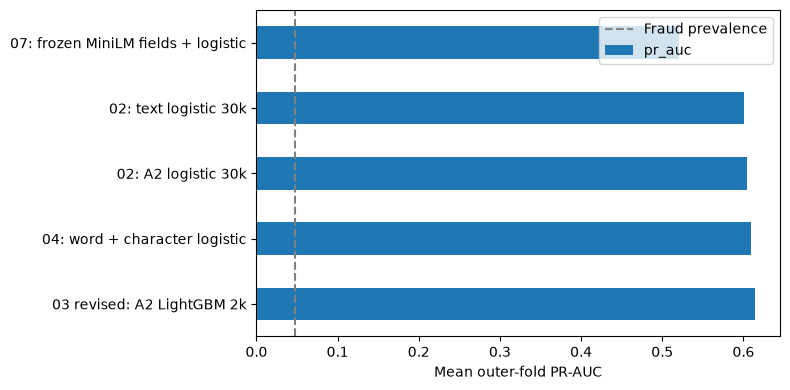

No reserved test data was read. No final fitted classifier has been exported.


In [13]:
print('Semantic comparison:', 'COMPLETE' if KEY in RESULTS else 'PENDING — references only')
summary = pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.sort_values('pr_auc', ascending=False)
display(summary[['pr_auc', 'precision', 'recall', 'f1', 'precision_top5pct', 'recall_top5pct']].round(3))
REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(REPORT_DIR / 'comparison_summary.csv')
comparisons = []
if KEY in RESULTS:
    for reference in RESULTS:
        if reference == KEY:
            continue
        for metric, higher in [('pr_auc', True), ('f1', True), ('recall', True), ('precision_top5pct', True)]:
            comparisons.append({'candidate': NAMES[KEY], 'reference': NAMES[reference], 'metric': metric,
                                **paired_comparison(RESULTS[KEY], RESULTS[reference], metric, higher)})
paired = pd.DataFrame(comparisons)
if not paired.empty:
    display(paired.round(3))
    paired.to_csv(REPORT_DIR / 'paired_differences.csv', index=False)
ax = summary.pr_auc.plot.barh(figsize=(8, 4), xlabel='Mean outer-fold PR-AUC')
ax.axvline(y.mean(), color='grey', linestyle='--', label='Fraud prevalence')
ax.legend()
plt.tight_layout()
plt.show()
print('No reserved test data was read. No final fitted classifier has been exported.')